# F1 Intelligence ML - model analysis

Inspect validation model comparisons, test metrics and feature importance.
Run `python scripts/train_all_models.py` and
`python scripts/evaluate_all_models.py` first.

In [1]:
import sys
from pathlib import Path

project_root = Path.cwd().resolve()
while not (project_root / 'config.py').exists() and project_root.parent != project_root:
    project_root = project_root.parent
if not (project_root / 'config.py').exists():
    raise RuntimeError('Run this notebook from the project or notebooks directory')
sys.path.insert(0, str(project_root))

import json
import pandas as pd
import matplotlib.pyplot as plt

import config

report = json.loads((config.REPORTS_DIR / 'evaluation_report.json').read_text(encoding='utf-8'))
for key, value in report['tasks'].items():
    print(key, value.get('algorithm'), value.get('metrics'))

winner/before_qualifying catboost {'log_loss': 0.11808354663282909, 'brier': 0.034234892364286125, 'n_rows': 2278, 'accuracy': 0.48214285714285715, 'top3_hit_rate': 0.7678571428571429, 'n_races': 112}
podium/before_qualifying catboost {'log_loss': 0.2606096899673166, 'brier': 0.08171151363824072, 'n_rows': 2278, 'precision': 0.5565476190476192, 'recall': 0.5565476190476192, 'f1': 0.5565476190476192, 'exact_set_accuracy': 0.05357142857142857, 'n_races': 112}
classification/before_qualifying lightgbm_ranker {'mae': 3.7761194029850746, 'rmse': 5.183464626209741, 'r2': 0.22967619688719676, 'n_rows': 2278, 'mae_classified': 3.772346983707618, 'rmse_classified': 5.180621344637393, 'spearman': 0.6083539959826244, 'ndcg_at_10': 0.7710323559684256, 'ranking_accuracy': 0.7365343795014017, 'top1_accuracy': 0.35714285714285715, 'podium_precision_at_3': 0.5148809523809523, 'n_races': 112}
driver_performance/before_qualifying lightgbm {'finish_mae': 3.858746105497172, 'finish_rmse': 4.77309357248998

In [2]:
comparison = json.loads((config.TASK_DIRECTORIES['winner'] / 'after_qualifying' / 'comparison.json').read_text(encoding='utf-8'))
rows = []
for candidate in comparison['candidates']:
    rows.append({
        'algorithm': candidate['algorithm'],
        'score': candidate['score'],
        'log_loss': candidate['metrics'].get('log_loss'),
        'accuracy': candidate['metrics'].get('accuracy'),
    })
pd.DataFrame(rows).sort_values('score', ascending=False)

,algorithm,score,log_loss,accuracy
0,xgboost,-0.106346,0.106346,0.550000
1,lightgbm,-0.107305,0.107305,0.550000
2,catboost,-0.107884,0.107884,0.533333
3,catboost,-0.108181,0.108181,0.566667
4,xgboost,-0.109220,0.109220,0.583333
5,catboost,-0.109411,0.109411,0.466667
6,xgboost,-0.110300,0.110300,0.533333
7,hist_gradient_boosting,-0.111941,0.111941,0.483333
8,catboost,-0.113918,0.113918,0.483333
9,random_forest,-0.117296,0.117296,0.550000


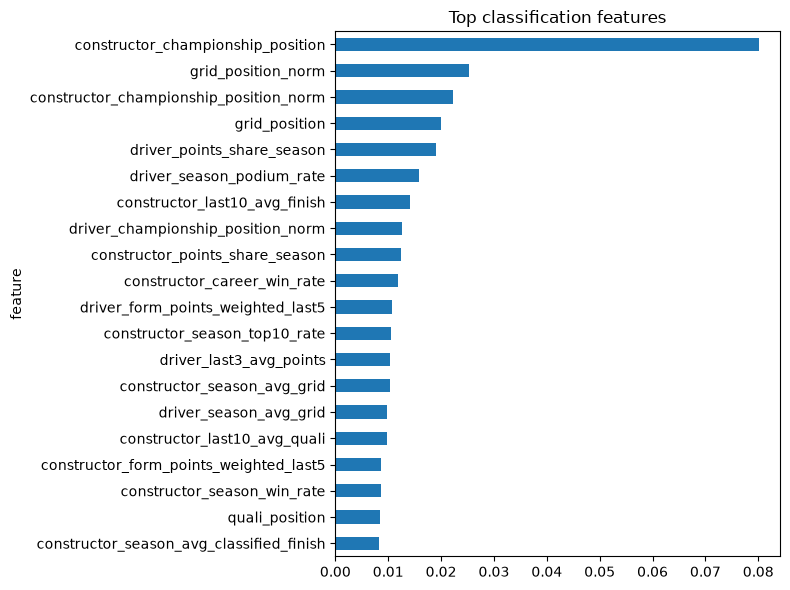

In [3]:
importance = pd.read_csv(config.TASK_DIRECTORIES['classification'] / 'after_qualifying' / 'feature_importance.csv')
if importance.empty:
    print('No feature importance available for this model.')
else:
    importance.head(20).set_index('feature')['importance'].plot(kind='barh', figsize=(8, 6))
    plt.gca().invert_yaxis()
    plt.title('Top classification features')
    plt.tight_layout()
    plt.show()